# Exercise 6.4 · Handwritten digit classification

## Data and model
MNIST consists of 28 by 28 grayscale images. A dense model receives a vector of 784 pixels per image. Labels are represented by one-hot vectors. The baseline uses 128 ReLU units, dropout of 0.2 and a ten-unit softmax output. Cross entropy scores the probability assigned to the correct digit. Accuracy is the fraction of images for which the highest output probability corresponds to the correct digit.

## Recorded architecture comparison
The table summarizes the saved runs. They used 60,000 training images, with the original test partition divided into 2,000 validation and 8,000 test images. The corrected code below instead draws validation data from the training split and keeps all 10,000 official test images for evaluation. It also explicitly divides grayscale pixels by 255.


| Hidden widths | Dropout placement | Train acc. | Val. acc. | Test acc. |
| --- | --- | --- | --- | --- |
| 128 | After layer 1 | 97.31% | 97.30% | 95.51% |
| 128, 64, 32, 16 | After layers 1 and 2 | 99.18% | 98.25% | 97.23% |
| 128, 64, 32, 16 | After layers 1–3 | 97.37% | 97.35% | 96.04% |
| 128, 64, 32, 16 (plotted) | After layers 1 and 2 | 96.89% | 97.20% | 95.86% |

The best saved architecture result was 97.23% test accuracy with four hidden layers and dropout after the first two. The run with dropout after three layers scored 96.04%. The plotted deep run, trained for ten epochs at batch size 65, got 95.86% with test cross entropy 0.1552. The difference between two runs of the same architecture shows why training settings and seeds matter when comparing depth. The saved learning curves and error analysis correspond to the plotted deep run. The baseline's recorded test accuracy comes from its separate results table.


![Figure](attachment:figure.png)

Figure 1. Recorded training and validation curves for the deep model.

![Figure](attachment:figure.png)

Figure 2. Confusion matrix of the recorded deep model. Misclassifications are the entries outside the diagonal.

![Figure](attachment:figure.png)

Figure 3. Predictions for the first ten test images in the saved run.

![Figure](attachment:figure.png)

Figure 4. Ten misclassified test images and their predicted probabilities.

![Figure](attachment:figure.png)

Figure 5. Additional misclassified digits from the saved run.

## Two parameter grid search
The saved grid varies hidden width and dropout at fixed learning rate 0.0001 and batch size 128 for ten epochs. Its source evaluates on the validation set. The plot's original “test accuracy” label therefore describes validation accuracy. The best observed configuration used 256 units and no dropout, reaching 96.60% validation accuracy. Increasing width helped at every tested dropout level under this training budget. The corrected code prints validation and test accuracy separately for every combination and selects using validation accuracy.


| Dropout | 32 units | 64 units | 128 units | 256 units |
| --- | --- | --- | --- | --- |
| 0.0 | 84.6% | 91.9% | 95.5% | 96.6% |
| 0.2 | 47.9% | 86.2% | 91.6% | 94.8% |
| 0.4 | 54.3% | 80.5% | 89.9% | 94.3% |
| 0.6 | 40.7% | 62.2% | 83.9% | 91.7% |

![Figure](attachment:figure.png)

Figure 6. Recorded grid search. The y axis reports validation accuracy.

## Five parameter random search
Each recorded trial trained for ten epochs. The best validation result was 96.80%, from trial 9 with 256 units, ELU, dropout 0.1, learning rate 0.0001 and batch size 64. Some very large learning rates led to accuracy near chance. Since several choices change between trials, the results cannot isolate the effect of any single parameter. The saved search stored validation accuracy only.


| Trial | Width | Dropout | LR | Batch | Act. | Val. acc. |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | 32 | 0.6 | 1e-2 | 128 | elu | 12.75% |
| 2 | 512 | 0.3 | 1e-5 | 256 | elu | 93.50% |
| 3 | 256 | 0.0 | 1e-2 | 64 | elu | 43.10% |
| 4 | 8 | 0.6 | 1e-4 | 256 | elu | 10.55% |
| 5 | 8 | 0.5 | 1e-4 | 256 | tanh | 67.05% |
| 6 | 128 | 0.5 | 1e-5 | 32 | elu | 77.40% |
| 7 | 128 | 0.1 | 1e-4 | 64 | relu | 93.90% |
| 8 | 32 | 0.5 | 1e-1 | 64 | sigmoid | 35.85% |
| 9 | 256 | 0.1 | 1e-4 | 64 | elu | 96.80% |
| 10 | 256 | 0.0 | 1e-2 | 256 | elu | 93.90% |
| 11 | 128 | 0.3 | 1e-2 | 128 | tanh | 81.60% |
| 12 | 256 | 0.3 | 1e-2 | 64 | elu | 35.65% |
| 13 | 256 | 0.3 | 1e-2 | 256 | elu | 92.30% |
| 14 | 8 | 0.5 | 1e-1 | 32 | elu | 10.75% |
| 15 | 128 | 0.0 | 1e-3 | 128 | tanh | 92.70% |
| 16 | 512 | 0.5 | 1e-5 | 32 | elu | 95.45% |
| 17 | 128 | 0.5 | 1e-2 | 128 | sigmoid | 87.90% |
| 18 | 512 | 0.0 | 1e-4 | 256 | tanh | 96.00% |
| 19 | 8 | 0.0 | 1e-2 | 16 | sigmoid | 73.75% |
| 20 | 32 | 0.0 | 1e-4 | 128 | tanh | 90.75% |

![Figure](attachment:figure.png)

Figure 7. Recorded resampling analysis based on validation classification error. It reuses the same 20 trials and does not estimate validation cross entropy.

## Search budget
The saved curve suggests that several trials improve the odds of finding a good configuration, with the gains tapering in this particular pool. The corrected experiment instead runs three independent searches of 20 trials each. At each budget it plots the mean and standard deviation of the running minimum validation cross entropy. This compares exactly three searches at every budget. The first search also reports test accuracy for all 20 configurations. These corrected experiments require a fresh run to produce new numeric outputs.


## Executable solution
The code below builds the requested baseline, compares architectures on a shared split, and measures both searches. Use the validation metrics for model selection. Test scores are reported to satisfy the exercise.

In [1]:
from itertools import product

import matplotlib.pyplot as plt
import numpy as np
from tensorflow import keras


In [2]:
# ------------------------
# --- Prepare the images and labels ---
# ------------------------
SEED = 640
keras.utils.set_random_seed(SEED)
(x_all, y_all), (x_test_images, y_test) = keras.datasets.mnist.load_data()
order = np.random.default_rng(SEED).permutation(len(y_all))
train, val = order[6000:], order[:6000]

def flatten(images):
    return images.reshape(-1, 784).astype('float32') / 255.0

x_train = flatten(x_all[train])
x_val = flatten(x_all[val])
x_test = flatten(x_test_images)
y_train = keras.utils.to_categorical(y_all[train], 10)
y_val = keras.utils.to_categorical(y_all[val], 10)
y_test_hot = keras.utils.to_categorical(y_test, 10)
print('Train, validation, test:', len(x_train), len(x_val), len(x_test))


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train, validation, test: 54000 6000 10000


In [3]:
# ------------------------
# --- Define and train a network ---
# ------------------------
def fit_model(widths, dropout, rate=0.001, batch=128, activation='relu',
              seed=SEED, evaluate_test=True):
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)
    # Add the hidden layers in the same order as the chosen widths.
    network_layers = [keras.Input(shape=(784,))]
    for layer_number, width in enumerate(widths):
        network_layers.append(keras.layers.Dense(width, activation=activation))
        if layer_number == 0:
            network_layers.append(keras.layers.Dropout(dropout))
    network_layers.append(keras.layers.Dense(10, activation='softmax'))
    model = keras.Sequential(network_layers)
    model.compile(optimizer=keras.optimizers.Adam(rate),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    history = model.fit(x_train, y_train, batch_size=batch, epochs=10,
                        validation_data=(x_val, y_val), verbose=0).history
    accuracy = None
    if evaluate_test:
        _, accuracy = model.evaluate(x_test, y_test_hot, verbose=0)
    return model, history, accuracy


Baseline test accuracy: 97.77%


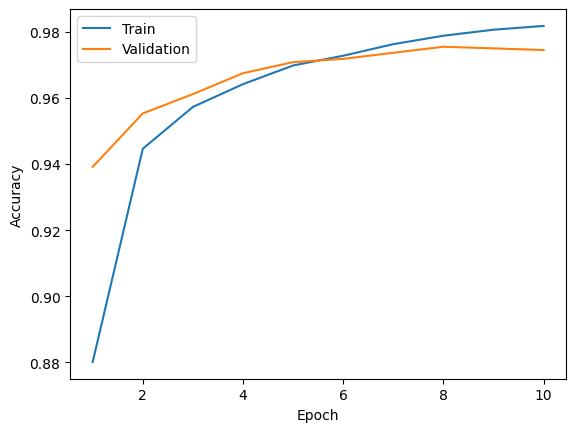

In [4]:
# ------------------------
# --- Train the 128 node network ---
# ------------------------
baseline, history, baseline_accuracy = fit_model((128,), 0.2)
print(f'Baseline test accuracy: {baseline_accuracy:.2%}')
epochs = np.arange(1, 11)
plt.plot(epochs, history['accuracy'], label='Train')
plt.plot(epochs, history['val_accuracy'], label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


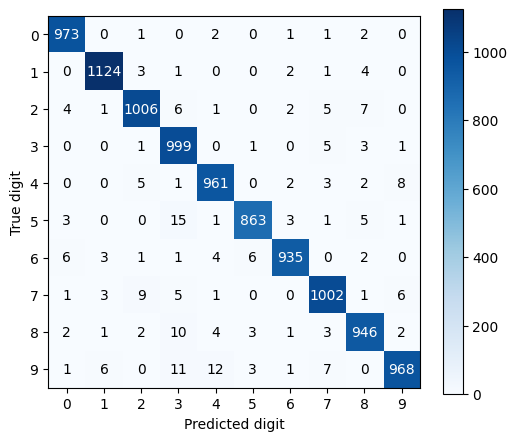

In [5]:
# ------------------------
# --- Check the confusion matrix ---
# ------------------------
prediction = baseline.predict(x_test, verbose=0).argmax(axis=1)
confusion = np.zeros((10, 10), dtype=int)
np.add.at(confusion, (y_test, prediction), 1)
fig, ax = plt.subplots(figsize=(6, 5))
heatmap = ax.imshow(confusion, cmap='Blues')
ax.set(xlabel='Predicted digit', ylabel='True digit',
       xticks=range(10), yticks=range(10))
for row, col in product(range(10), repeat=2):
    value = confusion[row, col]
    color = 'white' if value > confusion.max() / 2 else 'black'
    ax.text(col, row, str(value), ha='center', va='center', color=color)
fig.colorbar(heatmap, ax=ax)
plt.show()


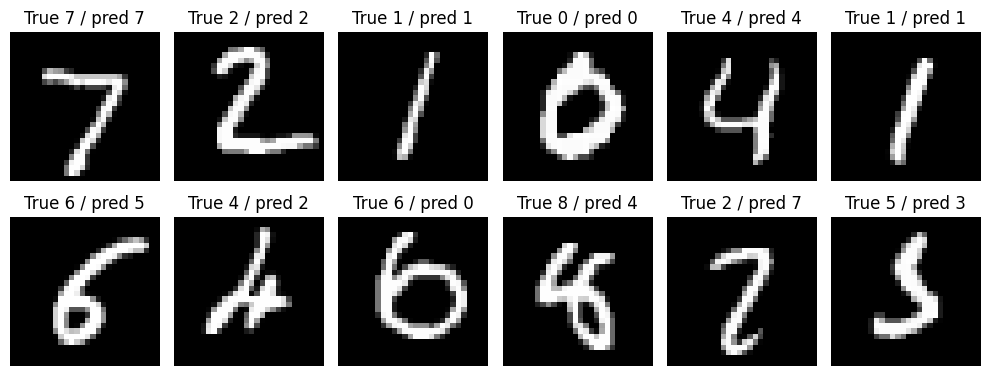

In [6]:
# ------------------------
# --- Show correct and incorrect predictions ---
# ------------------------
fig, axes = plt.subplots(2, 6, figsize=(10, 4))
for axs, mask in zip(axes, (prediction == y_test, prediction != y_test)):
    for ax, i in zip(axs, np.flatnonzero(mask)[:6]):
        ax.imshow(x_test_images[i], cmap='gray')
        ax.set_title(f'True {y_test[i]} / pred {prediction[i]}')
        ax.axis('off')
fig.tight_layout()
plt.show()


In [7]:
# ------------------------
# --- Compare different hidden layers ---
# ------------------------
print('Architecture, final validation accuracy, test accuracy')
print((128,), f"{history['val_accuracy'][-1]:.2%}",
      f'{baseline_accuracy:.2%}')
for widths in [(64,), (256,), (128, 64), (128, 64, 32, 16)]:
    _, h, test = fit_model(widths, 0.2)
    print(widths, f"{h['val_accuracy'][-1]:.2%}", f'{test:.2%}')


Architecture, final validation accuracy, test accuracy
(128,) 97.45% 97.77%
(64,) 96.87% 97.17%
(256,) 97.92% 97.85%
(128, 64) 97.42% 97.74%
(128, 64, 32, 16) 97.32% 97.49%


In [ ]:
# ------------------------
# --- Grid search over dropout and hidden nodes ---
# ------------------------
widths = [32, 64, 128, 256]
dropouts = [0.0, 0.2, 0.4, 0.6]
grid = []
for dropout, width in product(dropouts, widths):
    _, h, test = fit_model((width,), dropout, rate=0.0001)
    grid.append((width, dropout, h['val_accuracy'][-1], test))
    print(f'{width:3d} units, dropout {dropout:.1f}, '
          f"val {h['val_accuracy'][-1]:.2%}, test {test:.2%}")
print('Grid winner by validation accuracy:', max(grid, key=lambda row: row[2]))
for dropout in dropouts:
    test_by_width = [test for w, d, val, test in grid if d == dropout]
    plt.plot(widths, test_by_width, marker='o', label=f'Dropout {dropout:.1f}')
plt.xlabel('Hidden width')
plt.ylabel('Test accuracy')
plt.legend()
plt.show()


 32 units, dropout 0.0, val 91.80%, test 92.34%
 64 units, dropout 0.0, val 92.93%, test 93.60%
128 units, dropout 0.0, val 94.45%, test 94.58%
256 units, dropout 0.0, val 95.10%, test 95.68%
 32 units, dropout 0.2, val 90.97%, test 91.85%
 64 units, dropout 0.2, val 92.57%, test 93.51%


In [ ]:
# ------------------------
# --- Random search over five hyperparameters ---
# ------------------------
spaces = [
    [8, 32, 128, 256, 512],
    [0, 0.1, 0.2, 0.3, 0.5, 0.6],
    [1e-5, 1e-4, 1e-3, 1e-2, 1e-1],
    [16, 32, 64, 128, 256],
    ['relu', 'elu', 'sigmoid', 'tanh'],
]
candidates = list(product(*spaces))
loss_


In [ ]:
# ------------------------
# --- Plot the effect of the number of trials ---
# ------------------------
curves = []
for repeat in range(3):
    rng = np.random.default_rng(SEED + repeat)
    picks = rng.choice(len(candidates), 20, replace=False)
    trials = []
    for number, ix in enumerate(picks, 1):
        width, dropout, rate, batch, activation = candidates[ix]
        _, h, test = fit_model(
            (width,), dropout, rate=rate, batch=batch, activation=activation,
            seed=SEED + repeat * 20 + number, evaluate_test=(repeat == 0),
        )
        val_loss = h['val_loss'][-1]
        val_acc = h['val_accuracy'][-1]
        trials.append((candidates[ix], val_loss, val_acc, test))
        if repeat == 0:
            print(f'{number:2d} {candidates[ix]} '
                  f'val loss {val_loss:.4f}; val {val_acc:.2%}; test {test:.2%}')
    if repeat == 0:
        print('Random winner by validation accuracy:',
              max(trials, key=lambda row: row[2]))
    loss_curves.append(np.minimum.accumulate([trial[1] for trial in trials]))

curves = np.array(loss_curves)
mean = curves.mean(axis=0)
sd = curves.std(axis=0, ddof=1)
budget = np.arange(1, 21)
plt.plot(budget, mean, label='Mean best validation loss')
plt.fill_between(budget, mean - sd, mean + sd, alpha=0.25, label='±1 SD')
plt.xlabel('Number of trials')
plt.ylabel('Best validation cross entropy')
plt.legend()
plt.show()


## Archived run code
The following source cells document how the saved results and figures were produced. The executable cells above are the corrected version.